# Fine-tune pretrained ResNet-50 on CIFAR-10

This notebook fine-tunes the ImageNet-pretrained `microsoft/resnet-50` checkpoint for the 10 CIFAR-10 classes. It creates a stratified validation split from the official training data and does not use the official test data until final evaluation.

The processor resizes CIFAR-10 images to the pretrained model's expected 224-pixel input and applies its ImageNet normalization. The ImageNet classification head is replaced with a randomly initialized 10-class head.

References: [Hugging Face model card](https://huggingface.co/microsoft/resnet-50), [ResNet paper](https://arxiv.org/abs/1512.03385), [CIFAR-10 dataset](https://www.cs.toronto.edu/~kriz/cifar.html). The repository's project license is in `LICENCE`; review the checkpoint/model-card terms before redistributing model weights.

## 1. Imports and configuration

Run this notebook with the project environment's kernel. The packages used here are `torch`, `torchvision`, `transformers`, `Pillow`, `numpy`, and `matplotlib`.

In [1]:
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset
from torchvision import datasets, transforms
from transformers import AutoImageProcessor, ResNetForImageClassification

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck",
]
num_classes = len(class_names)
seed = 42
batch_size = 16
epochs = 5
validation_fraction = 0.10
checkpoint_name = "microsoft/resnet-50"
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_dir = project_root / "data" / "cifar10"
output_dir = project_root / "models" / "resnet50-cifar10"

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Training on: {device}")

/Users/antaunbobby/Desktop/AI Projects/resnet-practice/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Training on: mps


## 2. Load CIFAR-10 and create a stratified validation split

The official CIFAR-10 test split remains separate. Validation contains 10% of the original training images, sampled evenly from each class.

In [2]:
train_source = datasets.CIFAR10(root=data_dir, train=True, download=True)
test_source = datasets.CIFAR10(root=data_dir, train=False, download=True)

split_generator = torch.Generator().manual_seed(seed)
source_targets = torch.tensor(train_source.targets)
train_indices, validation_indices = [], []
for class_index in range(num_classes):
    class_indices = torch.where(source_targets == class_index)[0]
    class_indices = class_indices[
        torch.randperm(len(class_indices), generator=split_generator)
    ]
    validation_count = int(len(class_indices) * validation_fraction)
    validation_indices.extend(class_indices[:validation_count].tolist())
    train_indices.extend(class_indices[validation_count:].tolist())

print(
    f"Train: {len(train_indices):,}; validation: {len(validation_indices):,}; "
    f"test: {len(test_source):,}"
)

100%|██████████| 170M/170M [32:29<00:00, 87.5kB/s]   


Train: 45,000; validation: 5,000; test: 10,000


## 3. Preprocessing and data loaders

Training images receive random crop and horizontal flip augmentation. The Hugging Face image processor handles resizing and normalization for both training and evaluation images.

In [3]:
processor = AutoImageProcessor.from_pretrained(checkpoint_name)
train_augmentation = transforms.Compose([
    transforms.RandomCrop(32, padding=4, padding_mode="reflect"),
    transforms.RandomHorizontalFlip(),
])

class CIFAR10ForResNet(Dataset):
    def __init__(self, source, indices, image_processor, augment=False):
        self.source = source
        self.indices = indices
        self.image_processor = image_processor
        self.augment = augment

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image, label = self.source[self.indices[index]]
        if self.augment:
            image = train_augmentation(image)
        pixel_values = self.image_processor(
            images=image.convert("RGB"), return_tensors="pt"
        )["pixel_values"][0]
        return pixel_values, label

train_dataset = CIFAR10ForResNet(
    train_source, train_indices, processor, augment=True
)
validation_dataset = CIFAR10ForResNet(
    train_source, validation_indices, processor
)
test_dataset = CIFAR10ForResNet(
    test_source, list(range(len(test_source))), processor
)

train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True, num_workers=0
)
validation_loader = DataLoader(
    validation_dataset, batch_size=batch_size, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False, num_workers=0
)

sample_pixels, sample_label = train_dataset[0]
print(
    f"Processed image: {tuple(sample_pixels.shape)}; "
    f"label: {class_names[sample_label]}"
)

Processed image: (3, 224, 224); label: airplane


## 4. Load pretrained weights and replace the classifier

`ignore_mismatched_sizes=True` is expected here: the 1,000-class ImageNet head is replaced by a new 10-class CIFAR-10 head. The backbone starts from pretrained weights; the new classifier starts randomly initialized.

In [4]:
id2label = {index: name for index, name in enumerate(class_names)}
label2id = {name: index for index, name in id2label.items()}
model = ResNetForImageClassification.from_pretrained(
    checkpoint_name,
    num_labels=num_classes,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True,
).to(device)

# Use a smaller learning rate for pretrained features and a larger one for the new head.
optimizer = torch.optim.AdamW(
    [
        {"params": model.resnet.parameters(), "lr": 1e-5},
        {"params": model.classifier.parameters(), "lr": 1e-3},
    ],
    weight_decay=1e-4,
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=1
)
print(f"Classifier output classes: {model.config.num_labels}")

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.
Loading weights: 100%|██████████| 320/320 [00:00<00:00, 13609.59it/s]
[transformers] ResNetForImageClassification LOAD REPORT from: microsoft/resnet-50
Key                 | Status   |                                                                                             
--------------------+----------+---------------------------------------------------------------------------------------------
classifier.1.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 2048]) vs model:torch.Size([10, 2048])
classifier.1.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])            

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Classifier output classes: 10


## 5. Fine-tune and select the best checkpoint using validation accuracy

This trains the full network. Five epochs are a short starting run; increase `epochs` only after checking runtime and validation results. The best validation checkpoint is written to `models/resnet50-cifar10/`.

In [5]:
def run_epoch(data_loader, training):
    model.train(training)
    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    context = torch.enable_grad() if training else torch.inference_mode()
    with context:
        for pixel_values, labels in data_loader:
            pixel_values = pixel_values.to(device)
            labels = labels.to(device)
            outputs = model(pixel_values=pixel_values, labels=labels)

            if training:
                optimizer.zero_grad(set_to_none=True)
                outputs.loss.backward()
                optimizer.step()

            batch_count = labels.size(0)
            total_loss += outputs.loss.item() * batch_count
            total_correct += (outputs.logits.argmax(dim=1) == labels).sum().item()
            total_examples += batch_count

    return total_loss / total_examples, total_correct / total_examples

os.makedirs(output_dir, exist_ok=True)
best_validation_accuracy = -1.0
epochs_without_improvement = 0
early_stopping_patience = 3

for epoch in range(epochs):
    train_loss, train_accuracy = run_epoch(train_loader, training=True)
    validation_loss, validation_accuracy = run_epoch(
        validation_loader, training=False
    )
    scheduler.step(validation_accuracy)
    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"train loss {train_loss:.4f}, accuracy {train_accuracy:.2%} | "
        f"validation loss {validation_loss:.4f}, "
        f"accuracy {validation_accuracy:.2%}"
    )

    if validation_accuracy > best_validation_accuracy:
        best_validation_accuracy = validation_accuracy
        epochs_without_improvement = 0
        model.save_pretrained(output_dir)
        processor.save_pretrained(output_dir)
        print(f"Saved best validation checkpoint ({best_validation_accuracy:.2%}).")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= early_stopping_patience:
            print("Early stopping: validation accuracy stopped improving.")
            break

model = ResNetForImageClassification.from_pretrained(output_dir).to(device)
print(f"Best validation accuracy: {best_validation_accuracy:.2%}")

Epoch 1/5 | train loss 0.8148, accuracy 73.55% | validation loss 0.4183, accuracy 86.96%


Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 13.65it/s]

Saved best validation checkpoint (86.96%).


Epoch 2/5 | train loss 0.4806, accuracy 83.76% | validation loss 0.2755, accuracy 91.16%


Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 13.48it/s]

...

Epoch 5/5 | train loss 0.2905, accuracy 90.10% | validation loss 0.1851, accuracy 93.72%


Writing model shards: 100%|██████████| 1/1 [00:00<00:00, 11.95it/s]


Saved best validation checkpoint (93.72%).


Loading weights: 100%|██████████| 320/320 [00:00<00:00, 14484.19it/s]


Best validation accuracy: 93.72%


## 6. Final evaluation on the untouched CIFAR-10 test split

Test loss: 0.2087
Overall test accuracy: 93.67%

Per-class accuracy:
airplane  : 95.00%
automobile: 96.40%
bird      : 94.70%
cat       : 85.80%
deer      : 89.30%
dog       : 94.10%
frog      : 94.40%
horse     : 95.40%
ship      : 95.90%
truck     : 95.70%


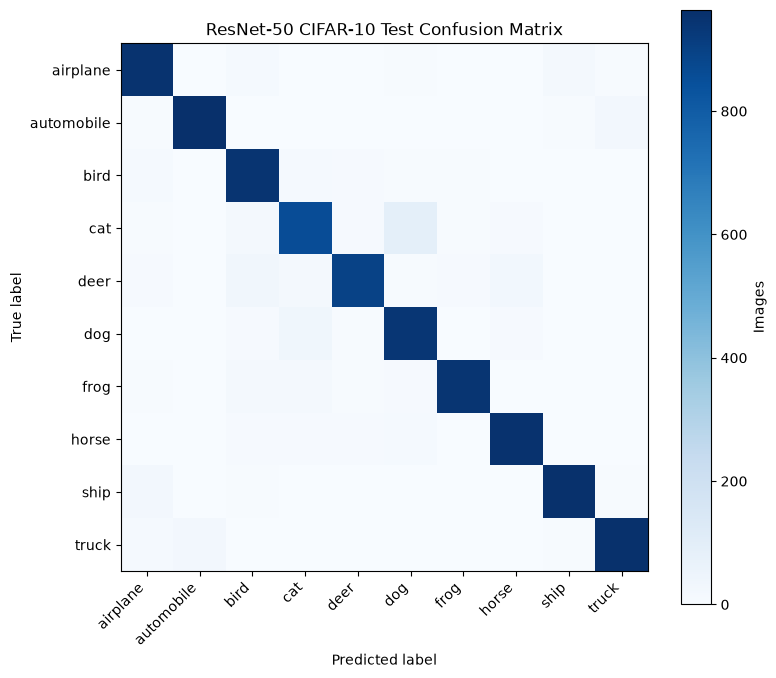

In [6]:
test_loss_total = 0.0
all_predictions, all_targets = [], []
model.eval()
with torch.inference_mode():
    for pixel_values, labels in test_loader:
        outputs = model(
            pixel_values=pixel_values.to(device), labels=labels.to(device)
        )
        test_loss_total += outputs.loss.item() * labels.size(0)
        logits = outputs.logits
        all_predictions.append(logits.argmax(dim=1).cpu())
        all_targets.append(labels)

y_pred = torch.cat(all_predictions)
y_true = torch.cat(all_targets)
test_loss = test_loss_total / len(test_dataset)
test_accuracy = (y_pred == y_true).float().mean().item()
confusion = torch.bincount(
    num_classes * y_true + y_pred, minlength=num_classes * num_classes
).reshape(num_classes, num_classes)

print(f"Test loss: {test_loss:.4f}")
print(f"Overall test accuracy: {test_accuracy:.2%}")
print("\nPer-class accuracy:")
for class_index, class_name in enumerate(class_names):
    class_total = confusion[class_index].sum().item()
    class_correct = confusion[class_index, class_index].item()
    print(f"{class_name:10s}: {class_correct / class_total:.2%}")

plt.figure(figsize=(8, 7))
plt.imshow(confusion.numpy(), cmap="Blues")
plt.colorbar(label="Images")
plt.xticks(range(num_classes), class_names, rotation=45, ha="right")
plt.yticks(range(num_classes), class_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("ResNet-50 CIFAR-10 Test Confusion Matrix")
plt.tight_layout()
plt.show()

## 7. Visualize a batch of test predictions

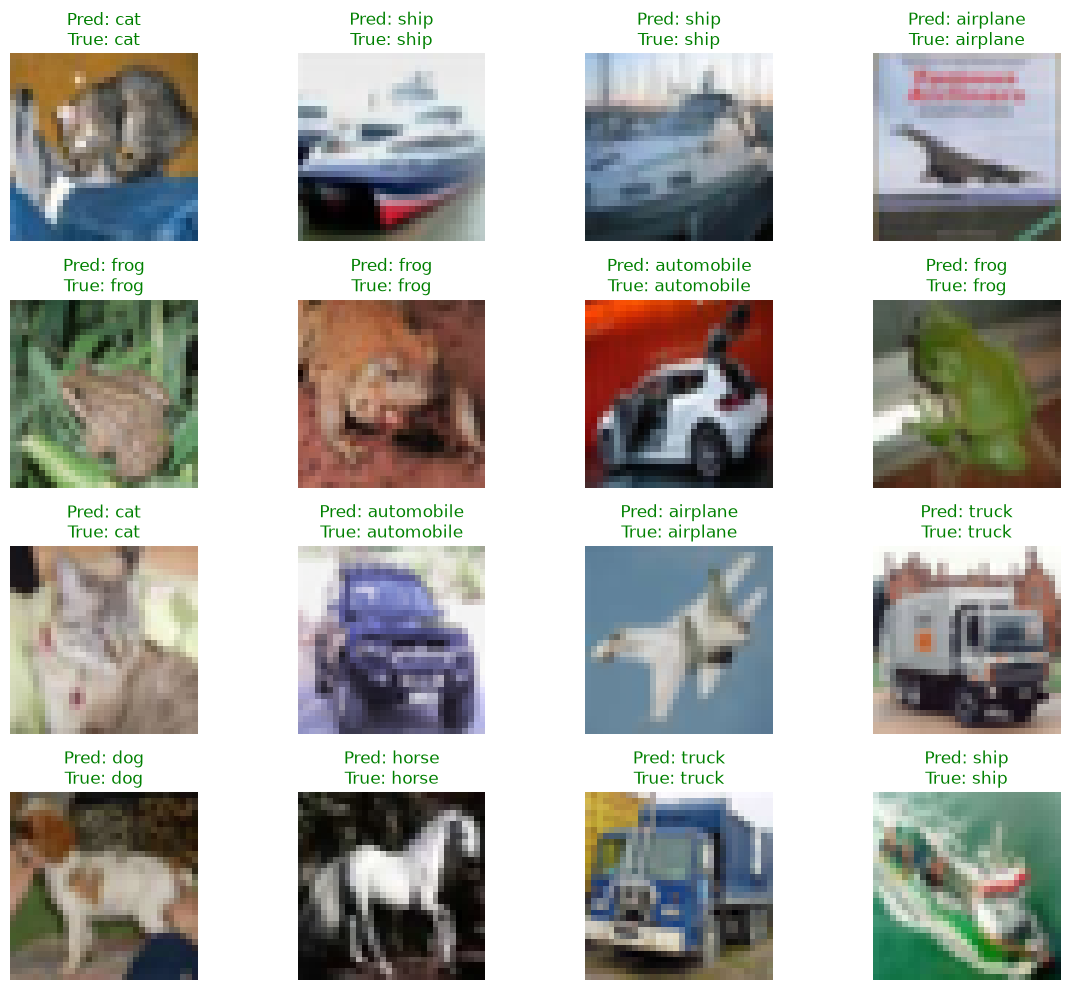

In [7]:
sample_count = 16
sample_batch = DataLoader(
    torch.utils.data.Subset(test_dataset, range(sample_count)),
    batch_size=sample_count,
    shuffle=False,
)
sample_pixels, sample_labels = next(iter(sample_batch))
with torch.inference_mode():
    sample_logits = model(pixel_values=sample_pixels.to(device)).logits
sample_predictions = sample_logits.argmax(dim=1).cpu()

fig, axes = plt.subplots(4, 4, figsize=(12, 10))
for index, axis in enumerate(axes.flat):
    image, true_label = test_source[index]
    predicted_label = sample_predictions[index].item()
    axis.imshow(image)
    axis.set_title(
        f"Pred: {class_names[predicted_label]}\n"
        f"True: {class_names[true_label]}",
        color="green" if predicted_label == true_label else "red",
    )
    axis.axis("off")
plt.tight_layout()
plt.show()